**Introduction et contexte :**

This notebook covers the **ridge** *regression model* in the context of our machine learning project.

Rappel de la formule venant du TP7:


 In the regression setting, given a training dataset $\mathcal{D} = \{(x^{(i)},y^{(i)})\}_{i=1}^n$, recall from the course that ridge regression aims to find the coefficients ${\beta}^\text{R}$ that mimimize the following optimization problem:
$${\beta}^\text{R} = \underset{{\beta}}{\text{argmin}} \sum_{i=1}^n \left(y^{(i)} - \beta_0 - \sum_{j=1}^p \beta_j x^{(i)}_{j}\right)^2 + \lambda \sum_{j=1}^p \beta_j^2,$$
where $\lambda$ is a hyperparameter controlling the amount of shrinkage applied to the coefficients $\beta_j$.

Aspects à prendre en compte :


*   Les estimateurs peuvent changer si les prédicteurs sont multiplié par une constante, dû à l'addition des coefficient au carré dans la formule. (CH5 sld 49/64)
*   Si on ne prend pas en compte le scaling, le prédicteur avec la plus grosse échelle peut dominer les estimateur de la **ridge** regression. (CH5 sld 50/64)
*   Il faut prendre en compte l'overfitting et l'underfitting.




**Librairies nécessaires :**

In [257]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    mean_squared_error,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.dummy import DummyRegressor
import sys
from pathlib import Path
import pandas as pd
import data_loader
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

**Récolte des données :**

In [258]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "ipynb" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
DATA_DIR = PROJECT_ROOT / "data"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))



features = data_loader.load_all_data()
results_train = pd.read_csv(DATA_DIR / "results_train.csv")

left_id_col = "CommuneID"
right_id_col = "Gemeinde-Nummer"
target_col = "Ja in Prozent"

# On renomme la vraie cible pour éviter les conflits de noms après merge
target_df = results_train[[right_id_col, target_col]].copy()
target_df = target_df.rename(columns={target_col: "target"})

train_df = features.merge(
    target_df,
    left_on=left_id_col,
    right_on=right_id_col,
    how="inner"
)

# y = variable à prédire
y = train_df["target"]

# X = variables explicatives
X = train_df.drop(columns=["target", right_id_col])

# Garder uniquement les colonnes numériques pour Ridge
X = X.select_dtypes(include="number")

# Retirer les identifiants
cols_to_remove = [col for col in ["CommuneID", "CantonID"] if col in X.columns]
X = X.drop(columns=cols_to_remove)

print("features shape:", features.shape)
print("results_train shape:", results_train.shape)
print("train_df shape:", train_df.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

features shape: (2325, 74)
results_train shape: (1559, 13)
train_df shape: (1559, 76)
X shape: (1559, 69)
y shape: (1559,)


,Stimmberechtigte,eingelegte Stimmzettel,Stimmbeteiligung,leere Stimmzettel,ungültige Stimmzettel,gültige Stimmen,Ja-Stimmen,Nein-Stimmen,Ja in Prozent,stpf,...,SP,SVP,EVP/CSP,GLP,BDP,PdA/Sol.,GPS,Small right-wing parties,lat,lon
0,1402.0,662.0,47.218260,5.0,0.0,657.0,206.0,451.0,31.354642,900.0,...,18.645940,30.929249,3.467063,8.435250,2.617442,0.167638,7.075094,4.888178,47.267500,8.485278
1,7186.0,2877.0,40.036181,49.0,0.0,2828.0,695.0,2133.0,24.575672,5385.0,...,19.080314,33.785785,5.464827,7.357860,4.164299,0.190049,6.211047,1.768197,47.281670,8.450230
2,3656.0,1690.0,46.225383,25.0,1.0,1664.0,404.0,1260.0,24.278846,2457.0,...,20.403265,29.100156,3.143003,11.862398,3.803108,0.112518,6.661066,1.915807,47.315556,8.469167
3,2505.0,1140.0,45.508982,14.0,0.0,1126.0,353.0,773.0,31.349911,1613.0,...,19.393305,34.937369,2.569875,8.748273,4.656087,0.193911,8.021665,1.825436,47.244722,8.534444
4,2515.0,1180.0,46.918489,12.0,0.0,1168.0,312.0,856.0,26.712329,1639.0,...,22.478008,30.114599,3.589299,9.625938,3.768864,0.227988,6.466387,1.840045,47.298611,8.449444


0    49.347258
1    45.572227
2    43.608653
3    49.331457
4    46.065129
Name: target, dtype: float64

**Division des données en 70% train et 30% test**

In [259]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=0
)

**Selection de la range de** $\lambda$

Pour l'instant la range de $\lambda$ va de 0.1 à 10 avec des steps de 0.1. Si nous trouvons un meilleur intervalle n'hésitons pas à le changer.
(les valeurs viennent du TP7)

In [260]:
alpha = np.logspace(-4, 4, 100) #Valeurs que peuvent prendre les lambda

**Trouver le meilleur** $λ$

In [261]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(fit_intercept=True))
])#Selection du modèle

grid = {
    "ridge__alpha": alpha
} #Créer une grille avec les valeurs de alpha

reg_ridge = GridSearchCV(
    model,
    grid,
    scoring="neg_root_mean_squared_error",
    cv=5
) #Scoring demandé dans le PDF du projet ?

reg_ridge.fit(X_train,y_train) #Fit le modèle avec les données d'entraînement

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ridge__alpha': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also

**Refit avec le meilleur** $λ$

In [262]:
best_lambda = reg_ridge.best_params_["ridge__alpha"] #Selectionner le meilleur lambda dans les paramètres du moèle fit

best_ridge = reg_ridge.best_estimator_ #Créer un modèle avec comme lambda la meilleure valeur trouvée plus haut

print("Meilleur lambda :", best_lambda)
print("Meilleure RMSE CV :", -reg_ridge.best_score_)

Meilleur lambda : 79.24828983539186
Meilleure RMSE CV : 7.019488640527756


(Note, sans standardisation, et avec alpha = np.arange(0.1, 10, 0.1) le meilleur lambda est 0.4, ici c'est 0.1 avec alpha = np.arange(0.1, 10, 0.1), et 79.2 avec alpha = np.logspace(-4, 4, 100))

**Vérification de l'underfitting et l'overfitting**

Nous savons que le modèle underfit s'il a une haute erreur d'entraînement et une haute erreur de test quand la la complexité du modèle évolue, autrement dit, le modèle underfit quand il a un haut biais.

Et qu'il overfit quand il a une haute erreur de test mais une basse erreur d'entraînement quand la complexité du modèle évolue, autrement dit, le modèle overfit quand il a une haute variance.

Pour verifier cela, comparons les performances de Ridge avec une baseline simple, celle qui est la moyenne du train.

**Vérification :**

In [263]:
y_pred_test = best_ridge.predict(X_test)
y_pred_train = best_ridge.predict(X_train)

train_mse = mean_squared_error(y_train, y_pred_train)
test_mse = mean_squared_error(y_test, y_pred_test)

train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

In [264]:
print("========== RIDGE ==========")
print("Erreur d'entraînement")
print(f"MSE  : {train_mse:.4f}")
print(f"RMSE : {train_rmse:.4f}")

print("\nErreur de test")
print(f"MSE  : {test_mse:.4f}")
print(f"RMSE : {test_rmse:.4f}")

========== RIDGE ==========
Erreur d'entraînement
MSE  : 45.0763
RMSE : 6.7139

Erreur de test
MSE  : 55.7279
RMSE : 7.4651


In [265]:
# =========================
# Baseline simple : moyenne du train
# =========================

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred_train = baseline.predict(X_train)
baseline_pred_test = baseline.predict(X_test)

baseline_train_mse = mean_squared_error(y_train, baseline_pred_train)
baseline_test_mse = mean_squared_error(y_test, baseline_pred_test)

baseline_train_rmse = np.sqrt(baseline_train_mse)
baseline_test_rmse = np.sqrt(baseline_test_mse)

print("\n========== BASELINE MOYENNE ==========")
print("Erreur d'entraînement baseline")
print(f"MSE  : {baseline_train_mse:.4f}")
print(f"RMSE : {baseline_train_rmse:.4f}")

print("\nErreur de test baseline")
print(f"MSE  : {baseline_test_mse:.4f}")
print(f"RMSE : {baseline_test_rmse:.4f}")


========== BASELINE MOYENNE ==========
Erreur d'entraînement baseline
MSE  : 104.4651
RMSE : 10.2208

Erreur de test baseline
MSE  : 107.1388
RMSE : 10.3508


In [266]:
# =========================
# Comparaison Ridge / baseline
# =========================

mse_improvement = (baseline_test_mse - test_mse) / baseline_test_mse
rmse_improvement = (baseline_test_rmse - test_rmse) / baseline_test_rmse

print("\n========== COMPARAISON À LA BASELINE ==========")
print(f"Amélioration MSE test par rapport à la baseline  : {mse_improvement:.2%}")
print(f"Amélioration RMSE test par rapport à la baseline : {rmse_improvement:.2%}")
# =========================
# Diagnostic overfitting / underfitting
# =========================

relative_gap = (test_rmse - train_rmse) / train_rmse if train_rmse != 0 else np.inf

print("\n========== DIAGNOSTIC ==========")
print(f"Écart absolu RMSE test - train : {test_rmse - train_rmse:.4f}")
print(f"Relative gap RMSE             : {relative_gap:.2%}")

if mse_improvement < 0.05:
    print("\nPossibilité d'underfitting : Ridge ne fait presque pas mieux que la baseline.")
elif relative_gap > 0.30:
    print("\nPossibilité d'overfitting : l'erreur test est nettement plus élevée que l'erreur d'entraînement.")
else:
    print("\nPas de signe évident d'underfitting ou d'overfitting.")


========== COMPARAISON À LA BASELINE ==========
Amélioration MSE test par rapport à la baseline  : 47.99%
Amélioration RMSE test par rapport à la baseline : 27.88%

========== DIAGNOSTIC ==========
Écart absolu RMSE test - train : 0.7512
Relative gap RMSE             : 11.19%

Pas de signe évident d'underfitting ou d'overfitting.


**Conclusion :**

Pas de signes d'underfitting ou d'overfitting

**Analyse des résultats**

========== MEILLEUR LAMBDA ==========
Meilleur lambda : 79.248290
Meilleure RMSE moyenne en cross-validation : 7.0195

========== TOP 10 DES LAMBDAS ==========


,lambda,mean_cv_RMSE,std_cv_RMSE,rank_test_score
73,79.248290,7.019489,0.243846,1
74,95.454846,7.020261,0.236619,2
72,65.793322,7.020821,0.249706,3
75,114.975700,7.023569,0.228229,4
71,54.622772,7.023909,0.254064,5
70,45.348785,7.028478,0.256837,6
76,138.488637,7.029922,0.218950,7
69,37.649358,7.034325,0.257994,8
36,0.081113,7.038755,0.296844,9
37,0.097701,7.038898,0.297483,10


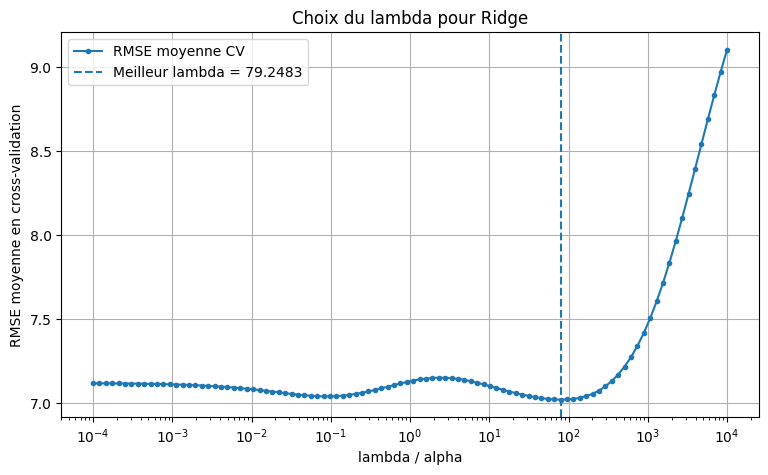

In [267]:
# =========================
# Résultats de la cross-validation Ridge
# =========================

cv_results = pd.DataFrame(reg_ridge.cv_results_).copy()

# Selon que Ridge est dans un Pipeline ou non, le nom du paramètre change
if "param_ridge__alpha" in cv_results.columns:
    alpha_col = "param_ridge__alpha"
elif "param_alpha" in cv_results.columns:
    alpha_col = "param_alpha"
else:
    raise KeyError("Impossible de trouver la colonne alpha dans cv_results.")

# Création des colonnes utiles
cv_results["lambda"] = cv_results[alpha_col].astype(float)
cv_results["mean_cv_RMSE"] = -cv_results["mean_test_score"]
cv_results["std_cv_RMSE"] = cv_results["std_test_score"]

# Tri pour affichage
cv_results_sorted = cv_results.sort_values("lambda")

print("========== MEILLEUR LAMBDA ==========")
print(f"Meilleur lambda : {best_lambda:.6f}")
print(f"Meilleure RMSE moyenne en cross-validation : {-reg_ridge.best_score_:.4f}")

print("\n========== TOP 10 DES LAMBDAS ==========")
display(
    cv_results[["lambda", "mean_cv_RMSE", "std_cv_RMSE", "rank_test_score"]]
    .sort_values("mean_cv_RMSE")
    .head(10)
)

# =========================
# Graphe lambda -> RMSE CV
# =========================

plt.figure(figsize=(9, 5))

plt.plot(
    cv_results_sorted["lambda"],
    cv_results_sorted["mean_cv_RMSE"],
    marker="o",
    markersize=3,
    label="RMSE moyenne CV"
)

plt.axvline(
    best_lambda,
    linestyle="--",
    label=f"Meilleur lambda = {best_lambda:.4f}"
)

plt.xscale("log")
plt.xlabel("lambda / alpha")
plt.ylabel("RMSE moyenne en cross-validation")
plt.title("Choix du lambda pour Ridge")
plt.grid(True)
plt.legend()
plt.show()